In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data   

%matplotlib inline

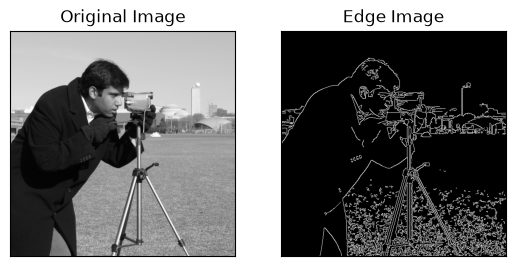

In [2]:
img = data.camera()

edges = cv2.Canny(img, 100, 200)

plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(edges, cmap='gray')
plt.title('Edge Image'), plt.xticks([]), plt.yticks([])
plt.show()

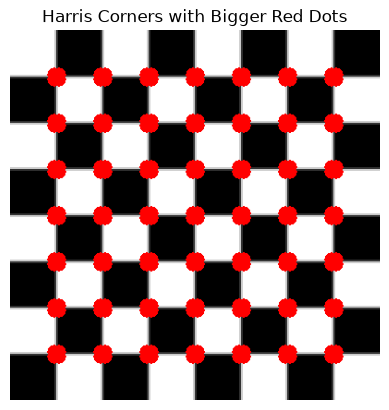

In [3]:
board = data.checkerboard()
image = cv2.cvtColor(board, cv2.COLOR_GRAY2BGR)
image = cv2.resize(image, (400, 400), interpolation=cv2.INTER_NEAREST)

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
gray = np.float32(gray)

harris = cv2.cornerHarris(gray, blockSize=2, ksize=3, k=0.04)

threshold = 0.01 * harris.max()
corner_coords = np.argwhere(harris > threshold)

for y, x in corner_coords:
    cv2.circle(image, (x, y), radius=7, color=(0, 0, 255), thickness=-1)  # -1 = filled

plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title('Harris Corners with Bigger Red Dots')
plt.axis('off')
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_19020\3536067126.py:18: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(img.ravel(), 256, [0, 256], color='gray')


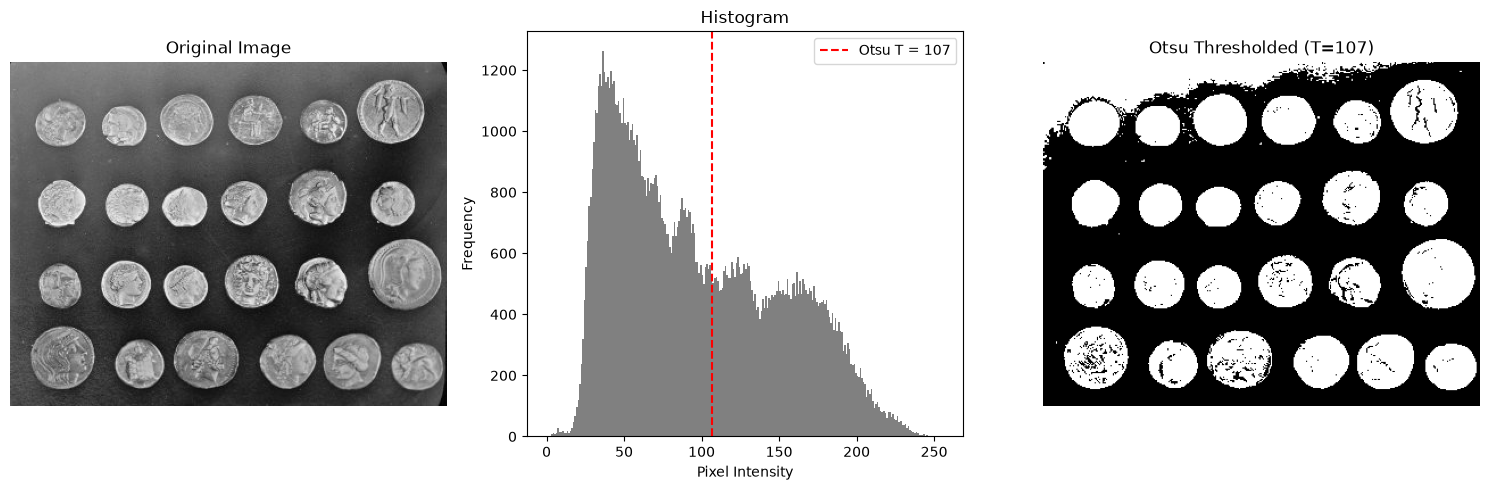

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

img = data.coins()

optimal_thresh, otsu_img = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

plt.figure(figsize=(15, 5))

plt.subplot(131)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(132)
plt.hist(img.ravel(), 256, [0, 256], color='gray')
plt.axvline(x=optimal_thresh, color='r', linestyle='--', label=f'Otsu T = {int(optimal_thresh)}')
plt.title('Histogram')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.legend()

plt.subplot(133)
plt.imshow(otsu_img, cmap='gray')
plt.title(f'Otsu Thresholded (T={int(optimal_thresh)})')
plt.axis('off')

plt.tight_layout()
plt.show()